# Implementación de un modelo de deep learning

## Alfredo Alejandro Soto Herrera - A01711368
### Modelo 2 — Transfer Learning con EfficientNetB0

Estrategia en dos fases:
1. Extracción de características: La cabeza empieza con pesos aleatorios, si entrenáramos todo de golpe, sus gradientes grandes destruirían lo aprendido por la base.
2. Fine-tuning: Ajustamos con mucho cuidado los rasgos de alto nivel de la base a los autos.

### Configuración y carga de datos

In [1]:
import os, sys, json, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

# Parámetros
IMG_SIZE = int(os.environ.get("IMG_SIZE", 224))
BATCH_SIZE = 32
SEEDS = [int(s) for s in os.environ.get("SEEDS", "42,123").split(",")]
DATA_SEED = 42

# Fase 1: base congelada
LR_P1 = 1e-3
MAX_EPOCHS_P1 = int(os.environ.get("EPOCHS_P1", 20))
PATIENCE_P1 = 6

# Fase 2: fine-tuning
LR_P2 = 1e-5
MAX_EPOCHS_P2 = int(os.environ.get("EPOCHS_P2", 30))
PATIENCE_P2 = 8
FINE_TUNE_LAYERS = 40

DROPOUT = 0.3
PRETRAINED = os.environ.get("PRETRAINED", "1") == "1"   # pesos de ImageNet

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NO (activa la GPU en Colab para entrenar más rápido)")
print("Semillas:", SEEDS)

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semillas: [42, 123]


In [2]:
IN_COLAB = "google.colab" in sys.modules
WORK_DIR = "/content" if IN_COLAB else os.path.abspath("./work_m2")
os.makedirs(WORK_DIR, exist_ok=True)

ZIP_PATH = "/content/drive/MyDrive/car_dataset_processed.zip"
DATA_DIR = os.path.join(WORK_DIR, "car_data")
SAVE_DIR = "/content/drive/MyDrive/car_models" if IN_COLAB else os.path.join(WORK_DIR, "models")
ADJ_DIR = os.path.join(SAVE_DIR, "ajustes")            # resultados del modelo 1
TL_DIR = os.path.join(SAVE_DIR, "transfer")            # resultados de este modelo

env_dir = os.environ.get("CAR_PROC_DIR")
if env_dir:
    DATA_DIR = env_dir
elif not os.path.isdir(os.path.join(DATA_DIR, "train")):
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

for root, dirs, _ in os.walk(DATA_DIR):
    if "train" in dirs and "val" in dirs and "test" in dirs:
        DATA_DIR = root
        break

if IN_COLAB and not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(TL_DIR, exist_ok=True)
print("DATA_DIR:", DATA_DIR)
print("Resultados del modelo 2 se guardan en:", TL_DIR)

Mounted at /content/drive
DATA_DIR: /content/car_data
Resultados del modelo 2 se guardan en: /content/drive/MyDrive/car_models/transfer


### Pipeline de datos

In [3]:
common = dict(image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int")
train_raw = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "train"), shuffle=True, seed=DATA_SEED, **common)
val_raw   = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "val"),   shuffle=False, **common)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
val_paths = val_raw.file_paths

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().prefetch(AUTOTUNE)
val_ds   = val_raw.cache().prefetch(AUTOTUNE)

def labels_of(ds):
    return np.concatenate([y.numpy() for _, y in ds])

y_train, y_val = labels_of(train_ds), labels_of(val_ds)
print("Clases:", class_names)
print("Imágenes -> train:", len(y_train), "| val:", len(y_val))

Found 1267 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Clases: ['Audi_R8', 'Audi_RS5', 'BMW_M3', 'BMW_M5', 'Chevrolet_Camaro', 'Ford_Mustang', 'Mercedes_AMG_GT', 'Nissan_GT_R', 'Porsche_911', 'Toyota_Supra']
Imágenes -> train: 1267 | val: 270


### Construcción del modelo

Entrada -> Augmentation -> EfficientNetB0 (sin su clasificador original) -> GlobalAveragePooling -> Dropout(0.3) -> Dense(10, softmax)

In [4]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
        layers.RandomBrightness(0.10, value_range=(0, 255)),
    ], name="augmentation")


def build_transfer_model(name="efficientnetb0_tl"):
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet" if PRETRAINED else None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = False # fase 1: base congelada

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, base


def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total

_m, _b = build_transfer_model()
tr, tot = count_params(_m)
print(f"Parámetros totales: {tot:,} | entrenables en la fase 1: {tr:,} ({tr / tot:.1%})")
print("Capas de la base:", len(_b.layers))
del _m, _b

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 4,062,381 | entrenables en la fase 1: 12,810 (0.3%)
Capas de la base: 238


Fase 1 (base congelada): Adam(1e-3), EarlyStopping con paciencia 6 sobre val_loss y restauración de los mejores pesos.

Fase 2 (fine-tuning): Se descongelan las últimas 40 capas de la base (excepto las BatchNormalization), se recompila con Adam(1e-5) y se entrena con paciencia 8.

In [5]:
RESULTS_PATH = os.path.join(TL_DIR, "transfer_results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
print("Corridas ya guardadas:", sorted(RESULTS.keys()))


def eval_model(model):
    tr_loss, tr_acc = model.evaluate(train_ds, verbose=0)
    va_loss, va_acc = model.evaluate(val_ds, verbose=0)
    y_pred = model.predict(val_ds, verbose=0).argmax(axis=1)
    f1_cls = f1_score(y_val, y_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)
    rec_cls = confusion_matrix(y_val, y_pred, labels=range(NUM_CLASSES)).diagonal() / np.bincount(y_val, minlength=NUM_CLASSES)
    return dict(train_acc=float(tr_acc), train_loss=float(tr_loss), val_acc=float(va_acc), val_loss=float(va_loss),
                val_macro_f1=float(f1_cls.mean()), f1_per_class=[float(v) for v in f1_cls],
                recall_per_class=[float(v) for v in rec_cls], y_pred=[int(v) for v in y_pred])


def progress_cb(tag):
    return keras.callbacks.LambdaCallback(on_epoch_end=lambda e, logs: print(
        f"   [{tag}] época {e + 1:>2} | acc {logs['accuracy']:.3f} | val_acc {logs['val_accuracy']:.3f} | val_loss {logs['val_loss']:.3f}")
        if (e + 1) % 5 == 0 else None)


def run_transfer(seed):
    key = f"transfer|{seed}"
    if key in RESULTS:
        print(f"[{key}] ya existe, se omite.")
        return RESULTS[key]

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model, base = build_transfer_model()
    t0 = time.time()

    # Fase 1
    model.compile(optimizer=keras.optimizers.Adam(LR_P1), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print(f"[{key}] FASE 1 (base congelada) | parámetros entrenables: {count_params(model)[0]:,}")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS_P1, verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_P1, restore_best_weights=True),
        progress_cb("F1")]).history
    p1 = eval_model(model)
    print(f"[{key}] fin fase 1 -> val_acc {p1['val_acc']:.3f} | macro-F1 {p1['val_macro_f1']:.3f}")

    # Fase 2
    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(LR_P2), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print(f"[{key}] FASE 2 (fine-tuning) | parámetros entrenables: {count_params(model)[0]:,}")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS_P2, verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_P2, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
        progress_cb("F2")]).history
    p2 = eval_model(model)
    elapsed = time.time() - t0

    res = dict(seed=seed, params_total=count_params(model)[1], seconds=float(elapsed),
               epochs_p1=len(h1["loss"]), epochs_p2=len(h2["loss"]),
               best_epoch_p1=int(np.argmin(h1["val_loss"]) + 1), best_epoch_p2=int(np.argmin(h2["val_loss"]) + 1),
               phase1={k: v for k, v in p1.items() if k not in ("y_pred", "f1_per_class", "recall_per_class")},
               hist1={k: [float(x) for x in v] for k, v in h1.items()},
               hist2={k: [float(x) for x in v] for k, v in h2.items()},
               **p2)
    RESULTS[key] = res
    json.dump(RESULTS, open(RESULTS_PATH, "w"))
    model.save(os.path.join(TL_DIR, f"modelo2_effnetb0_seed{seed}.keras"))
    print(f"[{key}] listo en {elapsed / 60:.1f} min | FINAL val_acc {p2['val_acc']:.3f} | macro-F1 {p2['val_macro_f1']:.3f} "
          f"| train_acc {p2['train_acc']:.3f}\n")
    return res

Corridas ya guardadas: ['transfer|123', 'transfer|42']


In [6]:
for seed in SEEDS:
    run_transfer(seed)

[transfer|42] ya existe, se omite.
[transfer|123] ya existe, se omite.


### Resultados

In [7]:
rows = []
for s in SEEDS:
    r = RESULTS[f"transfer|{s}"]
    rows.append({"Semilla": s,
                 "Fase 1 val acc (%)": round(100 * r["phase1"]["val_acc"], 1), "Final val acc (%)": round(100 * r["val_acc"], 1),
                 "Fase 1 macro-F1 (%)": round(100 * r["phase1"]["val_macro_f1"], 1), "Final macro-F1 (%)": round(100 * r["val_macro_f1"], 1),
                 "Train acc final (%)": round(100 * r["train_acc"], 1),
                 "Brecha train-val (pts)": round(100 * (r["train_acc"] - r["val_acc"]), 1),
                 "Épocas F1 / F2": f"{r['epochs_p1']} / {r['epochs_p2']}", "Minutos": round(r["seconds"] / 60, 1)})
per_seed = pd.DataFrame(rows).set_index("Semilla")
display(per_seed)

def mean_std(field, sub=None):
    vals = np.array([(RESULTS[f"transfer|{s}"][sub][field] if sub else RESULTS[f"transfer|{s}"][field]) for s in SEEDS])
    return vals.mean(), (vals.std(ddof=1) if len(vals) > 1 else np.nan)

m_acc, s_acc = mean_std("val_acc"); m_f1, s_f1 = mean_std("val_macro_f1")
p1_acc, _ = mean_std("val_acc", "phase1"); p1_f1, _ = mean_std("val_macro_f1", "phase1")
print(f"Modelo 2 (promedio de {len(SEEDS)} semillas): accuracy {m_acc:.1%}" + (f" ± {s_acc:.1%}" if not np.isnan(s_acc) else "")
      + f" | macro-F1 {m_f1:.3f}" + (f" ± {s_f1:.3f}" if not np.isnan(s_f1) else ""))
print(f"Efecto del fine-tuning: {100 * (m_acc - p1_acc):+.1f} pts de accuracy | {100 * (m_f1 - p1_f1):+.1f} pts de macro-F1 (respecto al final de la fase 1)")

,Fase 1 val acc (%),Final val acc (%),Fase 1 macro-F1 (%),Final macro-F1 (%),Train acc final (%),Brecha train-val (pts),Épocas F1 / F2,Minutos
Semilla,,,,,,,,
42,53.0,63.3,52.8,64.0,82.7,19.4,20 / 30,4.1
123,53.7,62.2,53.4,62.6,83.2,21.0,20 / 30,4.0


Modelo 2 (promedio de 2 semillas): accuracy 62.8% ± 0.8% | macro-F1 0.633 ± 0.010
Efecto del fine-tuning: +9.4 pts de accuracy | +10.2 pts de macro-F1 (respecto al final de la fase 1)


### Curvas de entrenamiento

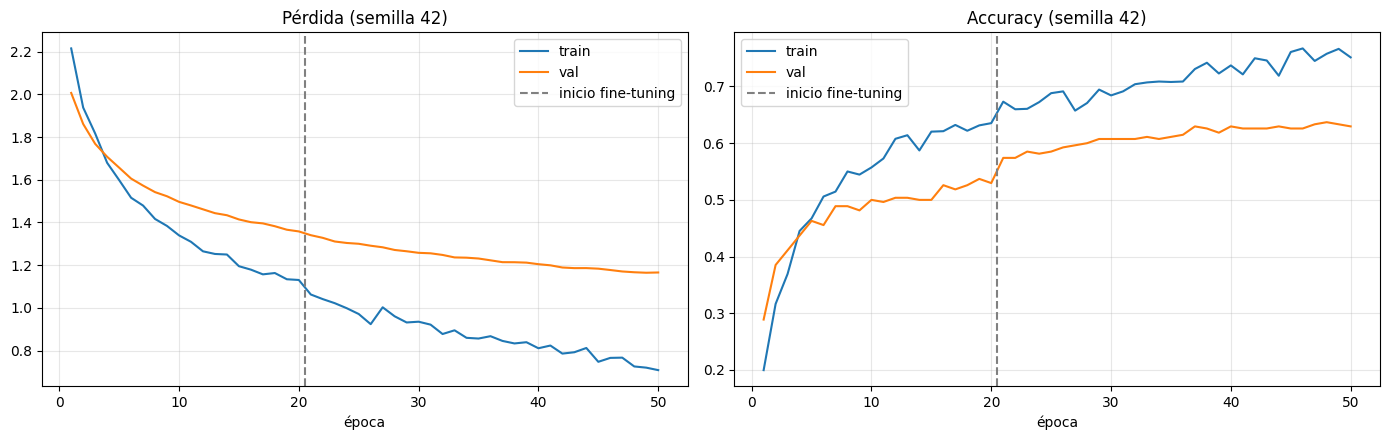

In [8]:
r = RESULTS[f"transfer|{SEEDS[0]}"]
h1, h2 = r["hist1"], r["hist2"]
n1 = len(h1["loss"])
loss = h1["loss"] + h2["loss"]; vloss = h1["val_loss"] + h2["val_loss"]
acc = h1["accuracy"] + h2["accuracy"]; vacc = h1["val_accuracy"] + h2["val_accuracy"]
ep = range(1, len(loss) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (tr_, va_, title) in zip(ax, [(loss, vloss, "Pérdida"), (acc, vacc, "Accuracy")]):
    a.plot(ep, tr_, label="train"); a.plot(ep, va_, label="val")
    a.axvline(n1 + 0.5, color="gray", ls="--", label="inicio fine-tuning")
    a.set_title(f"{title} (semilla {SEEDS[0]})"); a.set_xlabel("época"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

### Métricas por clase

In [9]:
f1_m2 = pd.DataFrame({"F1 (modelo 2)": np.mean([RESULTS[f"transfer|{s}"]["f1_per_class"] for s in SEEDS], axis=0),
                      "Recall (modelo 2)": np.mean([RESULTS[f"transfer|{s}"]["recall_per_class"] for s in SEEDS], axis=0)}, index=class_names)
f1_m2.loc["MACRO"] = f1_m2.mean()
display(f1_m2.style.background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1).format("{:.2f}"))

,F1 (modelo 2),Recall (modelo 2)
Audi_R8,0.72,0.68
Audi_RS5,0.75,0.76
BMW_M3,0.52,0.50
BMW_M5,0.66,0.79
Chevrolet_Camaro,0.61,0.64
Ford_Mustang,0.64,0.56
Mercedes_AMG_GT,0.62,0.55
Nissan_GT_R,0.62,0.65
Porsche_911,0.64,0.60
Toyota_Supra,0.54,0.57


### Matriz de confusión

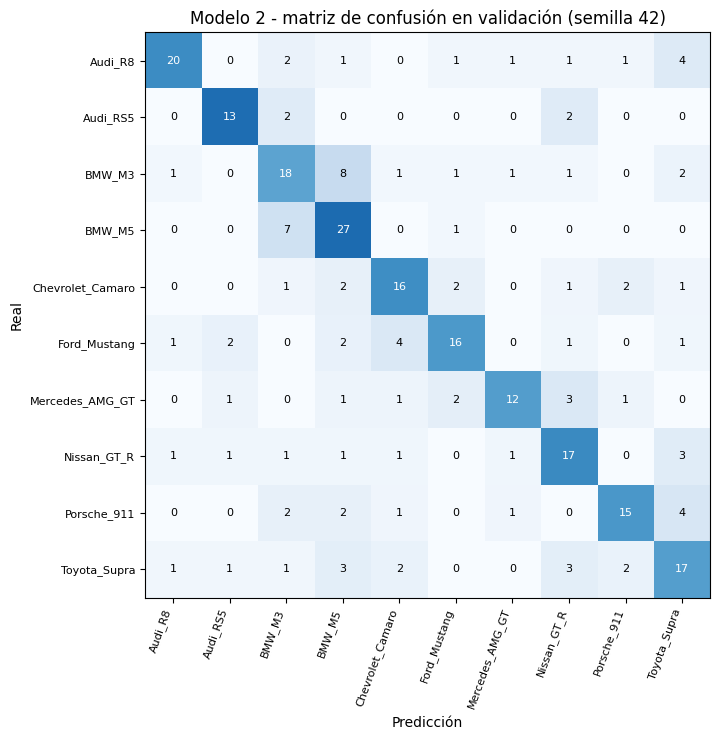

Confusiones más frecuentes:


,clase real,predicha como,veces
10,BMW_M3,BMW_M5,8
16,BMW_M5,BMW_M3,7
6,Audi_R8,Toyota_Supra,4
47,Porsche_911,Toyota_Supra,4
27,Ford_Mustang,Chevrolet_Camaro,4
34,Mercedes_AMG_GT,Nissan_GT_R,3
42,Nissan_GT_R,Toyota_Supra,3
51,Toyota_Supra,BMW_M5,3


In [10]:
def plot_cm(ax, y_pred, title):
    cm = confusion_matrix(y_val, y_pred, labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(title); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    return cm

fig, ax = plt.subplots(figsize=(8.5, 7.5))
y_pred_m2 = np.array(RESULTS[f"transfer|{SEEDS[0]}"]["y_pred"])
cm = plot_cm(ax, y_pred_m2, f"Modelo 2 - matriz de confusión en validación (semilla {SEEDS[0]})")
plt.tight_layout(); plt.show()

off = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
print("Confusiones más frecuentes:")
display(pd.DataFrame(off, columns=["clase real", "predicha como", "veces"]).sort_values("veces", ascending=False).head(8))

### Comparación contra el modelo 1

,Parámetros,Train acc (%),Val acc (%),Val macro-F1 (%)
Modelo,,,,
Modelo 1: CNN propia (E0_base),"392,426",40.1 ± 0.6,31.5 ± 0.5,27.3 ± 0.3
Modelo 2: EfficientNetB0 (transfer learning),"4,062,381",83.0 ± 0.3,62.8 ± 0.8,63.3 ± 1.0


Mejora del modelo 2 sobre el modelo 1: +31.3 puntos de accuracy | +36.0 puntos de macro-F1
Margen de error aproximado con 270 imágenes de validación: ±5.8 puntos -> la mejora supera ampliamente el ruido.


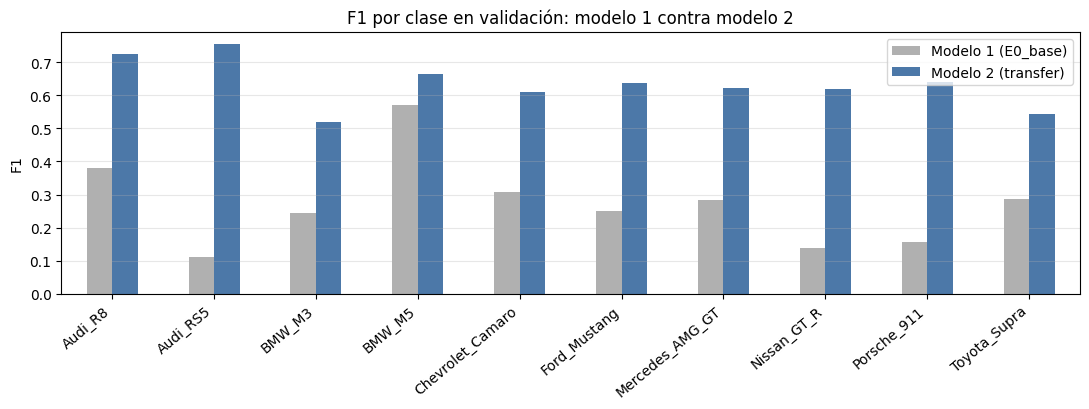

In [11]:
m1_path = os.path.join(ADJ_DIR, "adjust_results.json")
if not os.path.exists(m1_path):
    print("No se encontró", m1_path, "- ejecuta primero la libreta de ajustes del modelo 1 para ver esta comparación.")
else:
    R1 = json.load(open(m1_path))
    m1_keys = [k for k in R1 if k.startswith("E0_base|")]
    m1_acc = np.array([R1[k]["val_acc"] for k in m1_keys]); m1_f1 = np.array([R1[k]["val_macro_f1"] for k in m1_keys])
    m1_tr = np.array([R1[k]["train_acc"] for k in m1_keys])
    m2_acc = np.array([RESULTS[f"transfer|{s}"]["val_acc"] for s in SEEDS]); m2_f1 = np.array([RESULTS[f"transfer|{s}"]["val_macro_f1"] for s in SEEDS])
    m2_tr = np.array([RESULTS[f"transfer|{s}"]["train_acc"] for s in SEEDS])

    def f(a):
        return f"{100 * a.mean():.1f}" + (f" ± {100 * a.std(ddof=1):.1f}" if len(a) > 1 else "")

    comp = pd.DataFrame({
        "Modelo": ["Modelo 1: CNN propia (E0_base)", "Modelo 2: EfficientNetB0 (transfer learning)"],
        "Parámetros": [f"{R1[m1_keys[0]]['params']:,}", f"{RESULTS[f'transfer|{SEEDS[0]}']['params_total']:,}"],
        "Train acc (%)": [f(m1_tr), f(m2_tr)], "Val acc (%)": [f(m1_acc), f(m2_acc)], "Val macro-F1 (%)": [f(m1_f1), f(m2_f1)],
    }).set_index("Modelo")
    display(comp)

    gain = 100 * (m2_acc.mean() - m1_acc.mean())
    noise = 1.96 * np.sqrt(m2_acc.mean() * (1 - m2_acc.mean()) / len(y_val)) * 100
    print(f"Mejora del modelo 2 sobre el modelo 1: {gain:+.1f} puntos de accuracy | {100 * (m2_f1.mean() - m1_f1.mean()):+.1f} puntos de macro-F1")
    print(f"Margen de error aproximado con {len(y_val)} imágenes de validación: ±{noise:.1f} puntos ->",
          "la mejora supera ampliamente el ruido." if gain > 2 * noise else ("la mejora supera el ruido." if gain > noise else "la mejora está dentro del ruido."))

    f1_cmp = pd.DataFrame({"Modelo 1 (E0_base)": np.mean([R1[k]["f1_per_class"] for k in m1_keys], axis=0),
                           "Modelo 2 (transfer)": np.mean([RESULTS[f"transfer|{s}"]["f1_per_class"] for s in SEEDS], axis=0)}, index=class_names)
    ax = f1_cmp.plot.bar(figsize=(11, 4.2), color=["#B0B0B0", "#4C78A8"], title="F1 por clase en validación: modelo 1 contra modelo 2")
    ax.set_ylabel("F1"); ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

### Análisis de errores

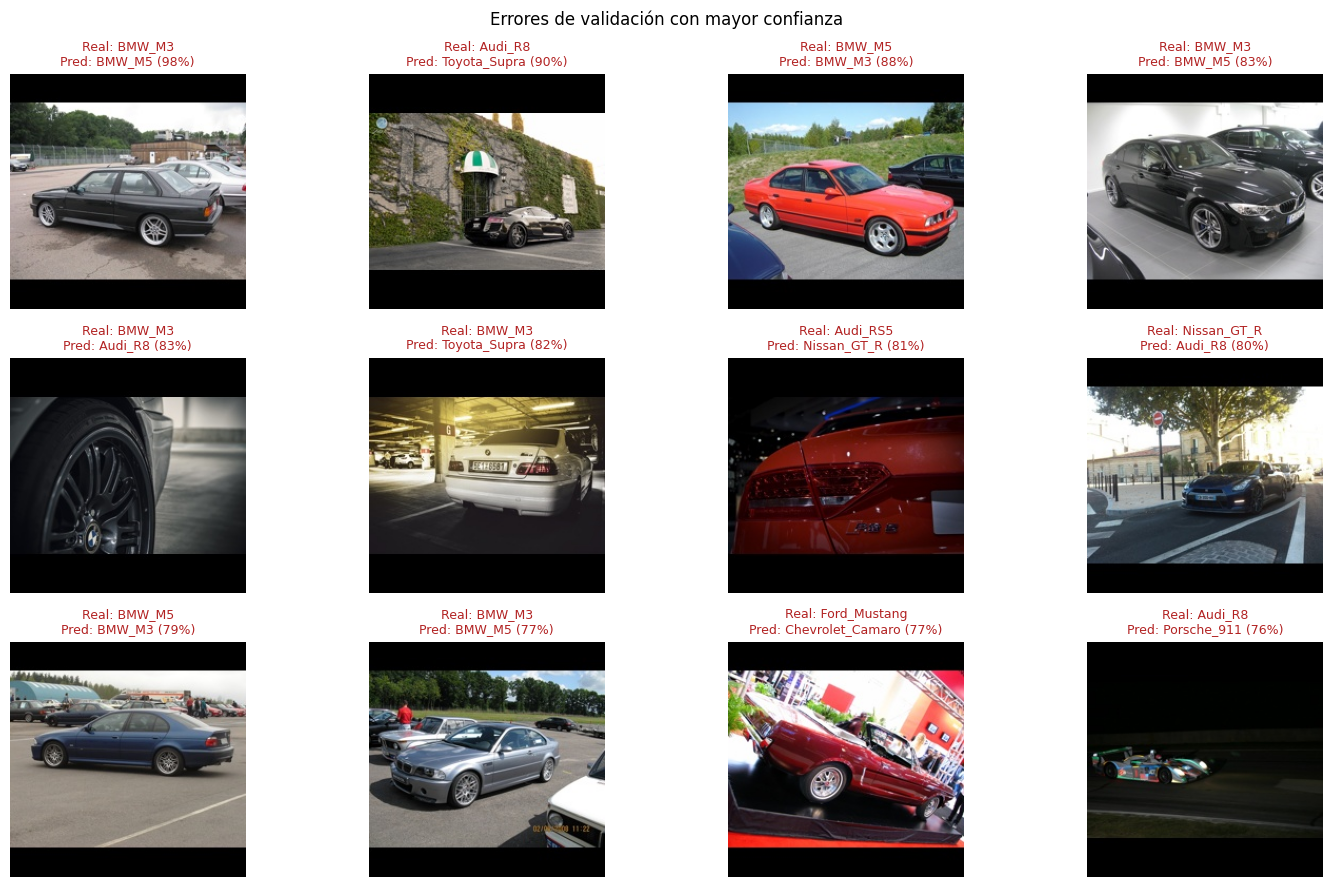

Errores totales en validación: 99 de 270


In [12]:
model_path = os.path.join(TL_DIR, f"modelo2_effnetb0_seed{SEEDS[0]}.keras")
model2 = keras.models.load_model(model_path)
probs = model2.predict(val_ds, verbose=0)
y_pred = probs.argmax(axis=1); conf = probs.max(axis=1)

wrong = np.where(y_pred != y_val)[0]
wrong = wrong[np.argsort(-conf[wrong])][:12]
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(val_paths[i]).convert("RGB"))
    ax.set_title(f"Real: {class_names[y_val[i]]}\nPred: {class_names[y_pred[i]]} ({conf[i]:.0%})", fontsize=9, color="firebrick")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Errores de validación con mayor confianza"); plt.tight_layout(); plt.show()
print(f"Errores totales en validación: {(y_pred != y_val).sum()} de {len(y_val)}")

### Evaluación final en test

Found 270 files belonging to 10 classes.


,Test accuracy (%),Test macro-F1 (%)
Modelo,,
Modelo 2 (EfficientNetB0),55.2,55.5
"Modelo 1 (CNN propia, E0_base)",33.7,27.7


                  precision    recall  f1-score   support

         Audi_R8      0.724     0.700     0.712        30
        Audi_RS5      0.696     0.842     0.762        19
          BMW_M3      0.417     0.469     0.441        32
          BMW_M5      0.571     0.686     0.623        35
Chevrolet_Camaro      0.526     0.400     0.455        25
    Ford_Mustang      0.407     0.458     0.431        24
 Mercedes_AMG_GT      0.923     0.500     0.649        24
     Nissan_GT_R      0.441     0.600     0.508        25
     Porsche_911      0.500     0.423     0.458        26
    Toyota_Supra      0.560     0.467     0.509        30

        accuracy                          0.552       270
       macro avg      0.577     0.554     0.555       270
    weighted avg      0.571     0.552     0.552       270



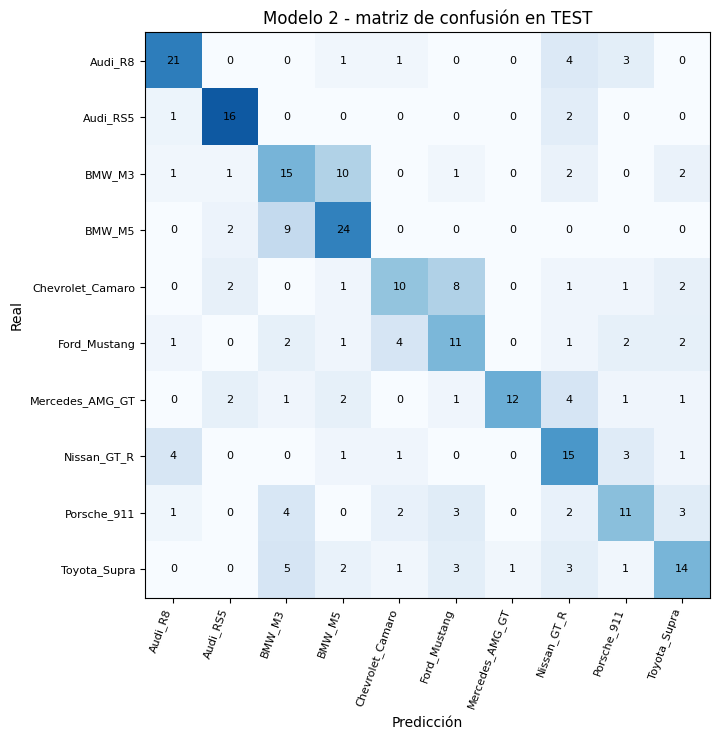

In [14]:
RUN_TEST_EVAL = True

if RUN_TEST_EVAL:
    test_raw = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "test"), shuffle=False, **common)
    test_ds = test_raw.cache().prefetch(AUTOTUNE)
    y_test = labels_of(test_ds)

    best_seed_m2 = max(SEEDS, key=lambda s: RESULTS[f"transfer|{s}"]["val_macro_f1"])
    models = {"Modelo 2 (EfficientNetB0)": os.path.join(TL_DIR, f"modelo2_effnetb0_seed{best_seed_m2}.keras")}
    if os.path.exists(os.path.join(ADJ_DIR, "adjust_results.json")):
        R1 = json.load(open(os.path.join(ADJ_DIR, "adjust_results.json")))
        k1 = max([k for k in R1 if k.startswith("E0_base|")], key=lambda k: R1[k]["val_macro_f1"])
        models["Modelo 1 (CNN propia, E0_base)"] = os.path.join(ADJ_DIR, f"E0_base_seed{k1.split('|')[1]}.keras")

    final_rows, preds_test = [], {}
    for name, path in models.items():
        m = keras.models.load_model(path)
        y_hat = m.predict(test_ds, verbose=0).argmax(axis=1)
        preds_test[name] = y_hat
        final_rows.append({"Modelo": name, "Test accuracy (%)": round(100 * (y_hat == y_test).mean(), 1),
                           "Test macro-F1 (%)": round(100 * f1_score(y_test, y_hat, average="macro"), 1)})
    display(pd.DataFrame(final_rows).set_index("Modelo"))

    name2 = "Modelo 2 (EfficientNetB0)"
    print(classification_report(y_test, preds_test[name2], target_names=class_names, digits=3, zero_division=0))
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    cm_t = confusion_matrix(y_test, preds_test[name2], labels=range(NUM_CLASSES))
    ax.imshow(cm_t / cm_t.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm_t[i, j], ha="center", va="center", fontsize=8)
    ax.set_title("Modelo 2 - matriz de confusión en TEST"); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    plt.tight_layout(); plt.show()
else:
    print("Evaluación en test desactivada.")